In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, importlib
ROOT = "/content/drive/MyDrive/simuteh-2330511091"
SRC = f"{ROOT}/src"
if SRC not in sys.path:
    sys.path.insert(0, SRC)
importlib.invalidate_caches()
os.chdir(f"{ROOT}/notebook")

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak, statistik
print("OK", os.getcwd())

Mounted at /content/drive
OK /content/drive/MyDrive/simuteh-2330511091/notebook


teh_041.png {'rerata': 172.5, 'simpangan_baku': 45.8, 'min': 55, 'maks': 241, 'persen_gelap': 0.0, 'persen_terang': 16.5}
teh_042.png {'rerata': 140.0, 'simpangan_baku': 46.9, 'min': 15, 'maks': 194, 'persen_gelap': 14.4, 'persen_terang': 0.0}
teh_043.png {'rerata': 213.3, 'simpangan_baku': 26.1, 'min': 133, 'maks': 252, 'persen_gelap': 0.0, 'persen_terang': 77.4}
teh_044.png {'rerata': 156.2, 'simpangan_baku': 17.6, 'min': 95, 'maks': 204, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_045.png {'rerata': 131.6, 'simpangan_baku': 58.0, 'min': 31, 'maks': 252, 'persen_gelap': 0.8, 'persen_terang': 17.4}


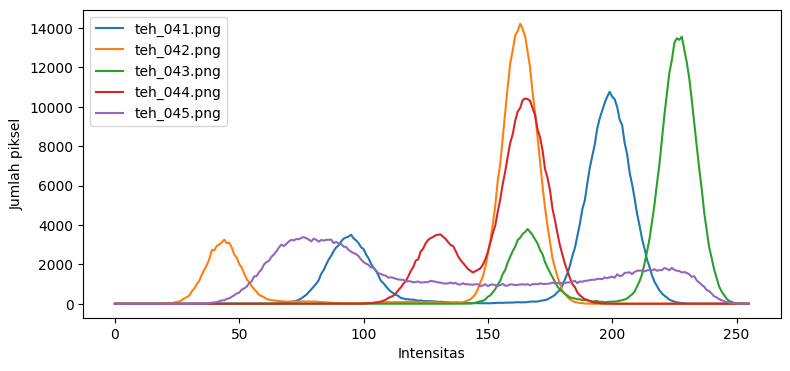

In [ ]:
nama_berat = ["teh_041.png", "teh_042.png", "teh_043.png", "teh_044.png", "teh_045.png"]
plt.figure(figsize=(9, 4))
for nama in nama_berat:
    gray = cv2.cvtColor(baca(f"../data/sintetis/citra/{nama}"), cv2.COLOR_BGR2GRAY)
    print(nama, statistik(gray))
    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)
plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend()
plt.savefig("../hasil/b3_histogram_5kondisi.png", dpi=150)
plt.show()

In [ ]:
kondisi = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
baris = []
for kelas, awal in [("berat", 41), ("ringan", 21)]:
    for i in range(5):
        nama = f"teh_{awal + i:03d}.png"
        gray = cv2.cvtColor(baca(f"../data/sintetis/citra/{nama}"), cv2.COLOR_BGR2GRAY)
        st = statistik(gray)
        baris.append([nama, kelas, kondisi[i], st["rerata"], st["simpangan_baku"],
                      st["min"], st["maks"], st["persen_gelap"], st["persen_terang"]])
tabel9 = pd.DataFrame(baris, columns=["citra", "kelas", "kondisi", "rerata",
                                      "simp_baku", "min", "maks", "%gelap", "%terang"])
print(tabel9.to_string(index=False))
tabel9.to_csv("../hasil/b3_diagnosis.csv", index=False)

      citra  kelas        kondisi  rerata  simp_baku  min  maks  %gelap  %terang
teh_041.png  berat         normal   172.5       45.8   55   241     0.0     16.5
teh_042.png  berat          gelap   140.0       46.9   15   194    14.4      0.0
teh_043.png  berat         terang   213.3       26.1  133   252     0.0     77.4
teh_044.png  berat kontras_rendah   156.2       17.6   95   204     0.0      0.0
teh_045.png  berat       bayangan   131.6       58.0   31   252     0.8     17.4
teh_021.png ringan         normal   176.4       38.6   70   228     0.0      9.4
teh_022.png ringan          gelap   117.3       37.6   18   167    14.9      0.0
teh_023.png ringan         terang   214.7       26.8  142   254     0.0     73.4
teh_024.png ringan kontras_rendah   152.9       15.1  104   186     0.0      0.0
teh_025.png ringan       bayangan   123.4       53.6   33   246     0.5     11.7


In [ ]:
nama = "teh_045.png"                 # kondisi bayangan
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

rmin, rmax = np.percentile(gray, (2, 98))      # abaikan 2% piksel ekstrem
hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": np.clip((gray - rmin) / (rmax - rmin) * 255,
                      0, 255).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(clipLimit=2.0,
                             tileGridSize=(8, 8)).apply(gray),
}
for nm, c in hasil.items():
    print(f"{nm:10s} KB={kontras_bercak(c, md, mb):.2f} "
          f"sigma={c.std():.1f}")


asli       KB=1.13 sigma=58.0
negatif    KB=1.13 sigma=58.0
cerah+50   KB=1.13 sigma=53.5
kontras    KB=1.13 sigma=76.8
regang     KB=1.18 sigma=81.4
gamma0.5   KB=1.01 sigma=40.3
gamma1.8   KB=1.33 sigma=65.9
ekualisasi KB=0.96 sigma=73.4
CLAHE      KB=1.61 sigma=48.0


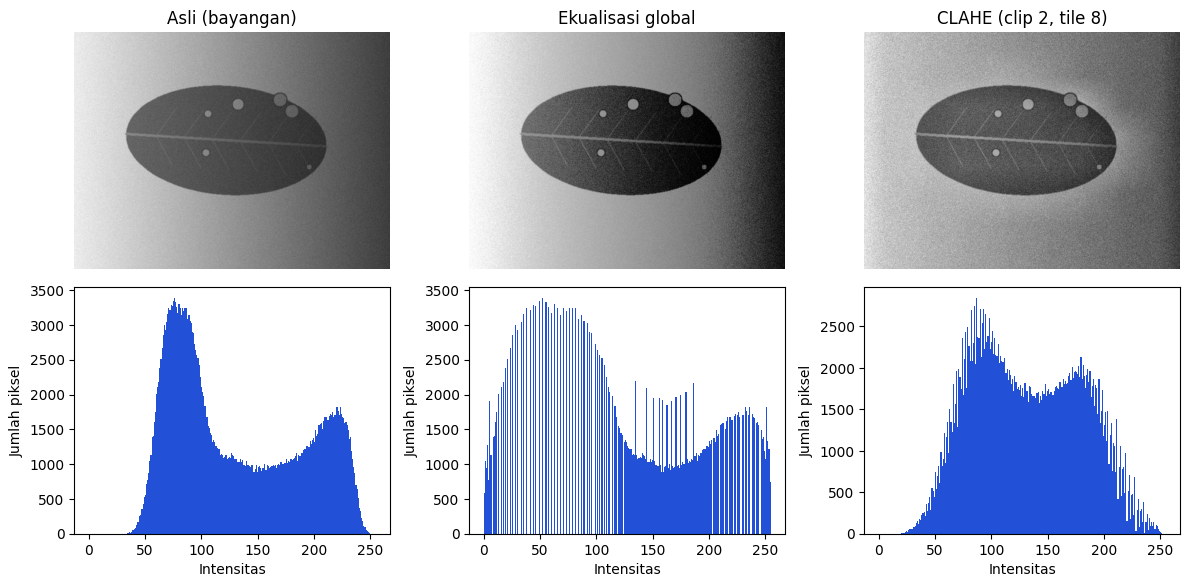

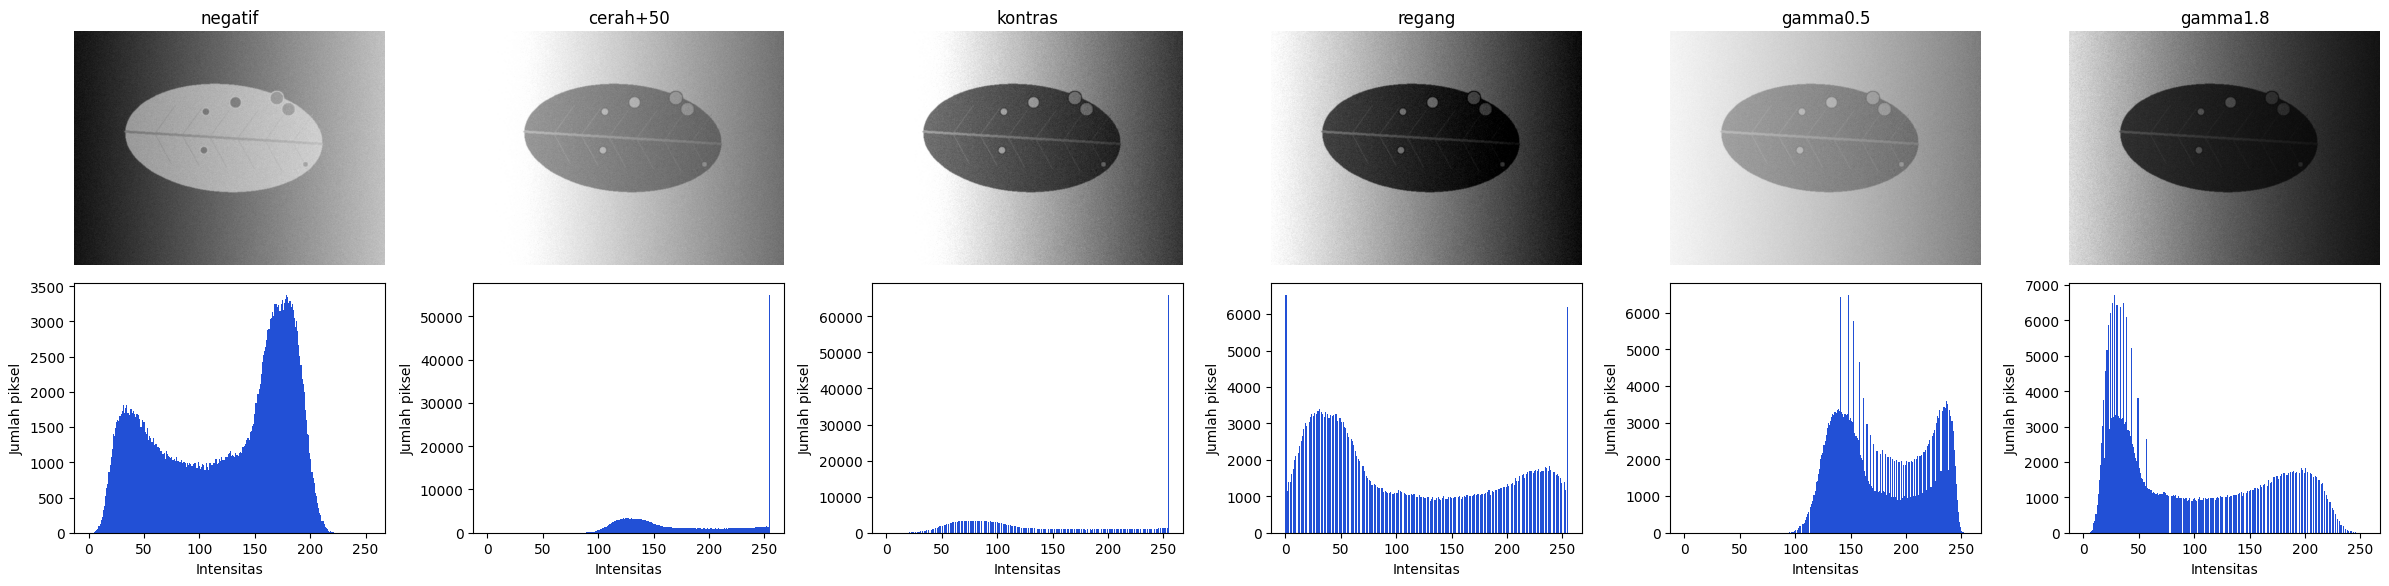

In [ ]:
def panel(daftar, judul, simpan):
    n = len(daftar)
    fig, ax = plt.subplots(2, n, figsize=(4 * n, 6))
    for i, (c, jd) in enumerate(zip(daftar, judul)):
        ax[0, i].imshow(c, cmap="gray", vmin=0, vmax=255); ax[0, i].set_title(jd); ax[0, i].axis("off")
        ax[1, i].hist(c.ravel(), bins=256, range=(0, 255), color="#2250d6")
        ax[1, i].set_xlabel("Intensitas"); ax[1, i].set_ylabel("Jumlah piksel")
    plt.tight_layout(); plt.savefig(simpan, dpi=150); plt.show()

panel([hasil["asli"], hasil["ekualisasi"], hasil["CLAHE"]],
      ["Asli (bayangan)", "Ekualisasi global", "CLAHE (clip 2, tile 8)"],
      "../hasil/b3_perbaikan_bayangan.png")
panel([hasil[k] for k in ["negatif", "cerah+50", "kontras", "regang", "gamma0.5", "gamma1.8"]],
      ["negatif", "cerah+50", "kontras", "regang", "gamma0.5", "gamma1.8"],
      "../hasil/b3_operasi_titik.png")

clip=1.0 tile=4: KB=1.85
clip=1.0 tile=8: KB=1.68
clip=1.0 tile=16: KB=1.66
clip=2.0 tile=4: KB=1.97
clip=2.0 tile=8: KB=1.61
clip=2.0 tile=16: KB=1.47
clip=4.0 tile=4: KB=1.74
clip=4.0 tile=8: KB=1.34
clip=4.0 tile=16: KB=1.30


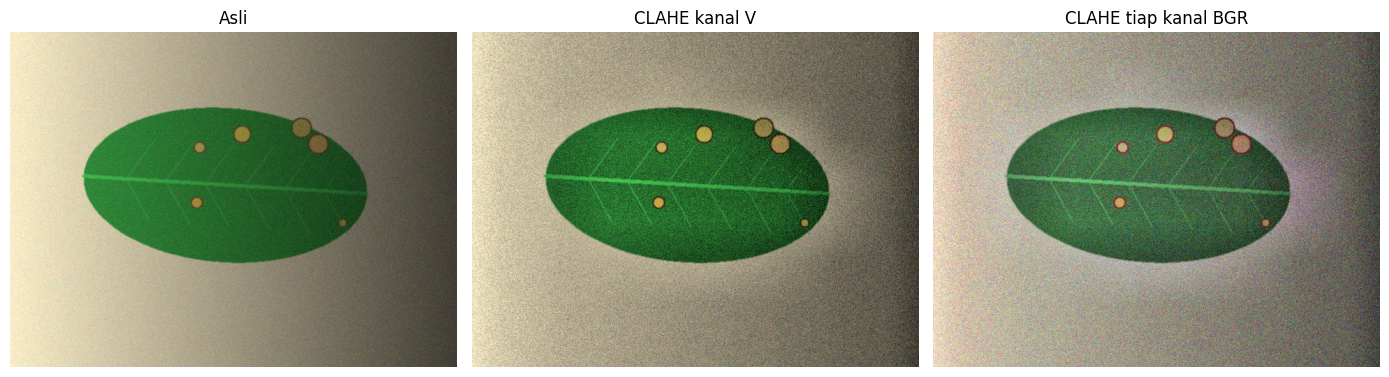

In [ ]:
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        c = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(gray)
        print(f"clip={clip} tile={tile}: KB={kontras_bercak(c, md, mb):.2f}")

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
via_bgr = cv2.merge([clahe.apply(c) for c in cv2.split(img)])
tampil([img, via_v, via_bgr], ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"])
plt.savefig("../hasil/b3_clahe_warna.png", dpi=150); plt.show()